# Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis Using Python

**Mohammed Rehaan**  
**005046243**  
**MSCS-634-B01: Advanced Big Data and Data Mining**  
**University of the Cumberlands**  
**Dr. Penmatsa**

## Lab purpose and dataset

This lab applies visualization, preprocessing, and statistical analysis to the UCI Online Retail dataset. The data contains transactions from a United Kingdom-based online retailer between December 2010 and December 2011. Each row describes a product line in an invoice, including its quantity, price, customer identifier, date, and country. The 541,909 records provide enough volume to show the effects of reduction and outlier handling on a realistic sales dataset.

The source file has eight original attributes. A `SalesAmount` field is calculated as `Quantity × UnitPrice` for analysis because it gives a direct measure of line-level sales value. Some invoices are cancellations or adjustments, which appear as nonpositive quantities or prices. Those records are reviewed and then excluded from sales-focused visualizations and statistics because they do not describe completed positive sales.

**Source:** Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")

DATA_PATH = Path("data/raw/Online Retail.xlsx")
SCREENSHOT_PATH = Path("screenshots")
PROCESSED_PATH = Path("data/processed/online_retail_lab_cleaned.csv")
SCREENSHOT_PATH.mkdir(exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

def save_table(dataframe, filename, title, max_rows=8):
    # Save a compact table image for the lab screenshot folder.
    view = dataframe.head(max_rows).copy()
    fig_height = max(2.4, 0.48 * (len(view) + 2))
    figure, axis = plt.subplots(figsize=(15, fig_height))
    axis.axis("off")
    table = axis.table(
        cellText=view.round(3).astype(str).values,
        colLabels=view.columns,
        cellLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.35)
    axis.set_title(title, fontsize=13, pad=14)
    figure.tight_layout()
    output = SCREENSHOT_PATH / filename
    figure.savefig(output, dpi=220, bbox_inches="tight")
    plt.close(figure)
    return output

def save_text(text, filename, title):
    figure, axis = plt.subplots(figsize=(12, 6))
    axis.axis("off")
    axis.text(0.01, 0.99, text, va="top", family="monospace", fontsize=9)
    axis.set_title(title, fontsize=13, pad=14)
    figure.tight_layout()
    output = SCREENSHOT_PATH / filename
    figure.savefig(output, dpi=220, bbox_inches="tight")
    plt.close(figure)
    return output

## Step 1: Data collection

Raw dataset shape: 541,909 rows and 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


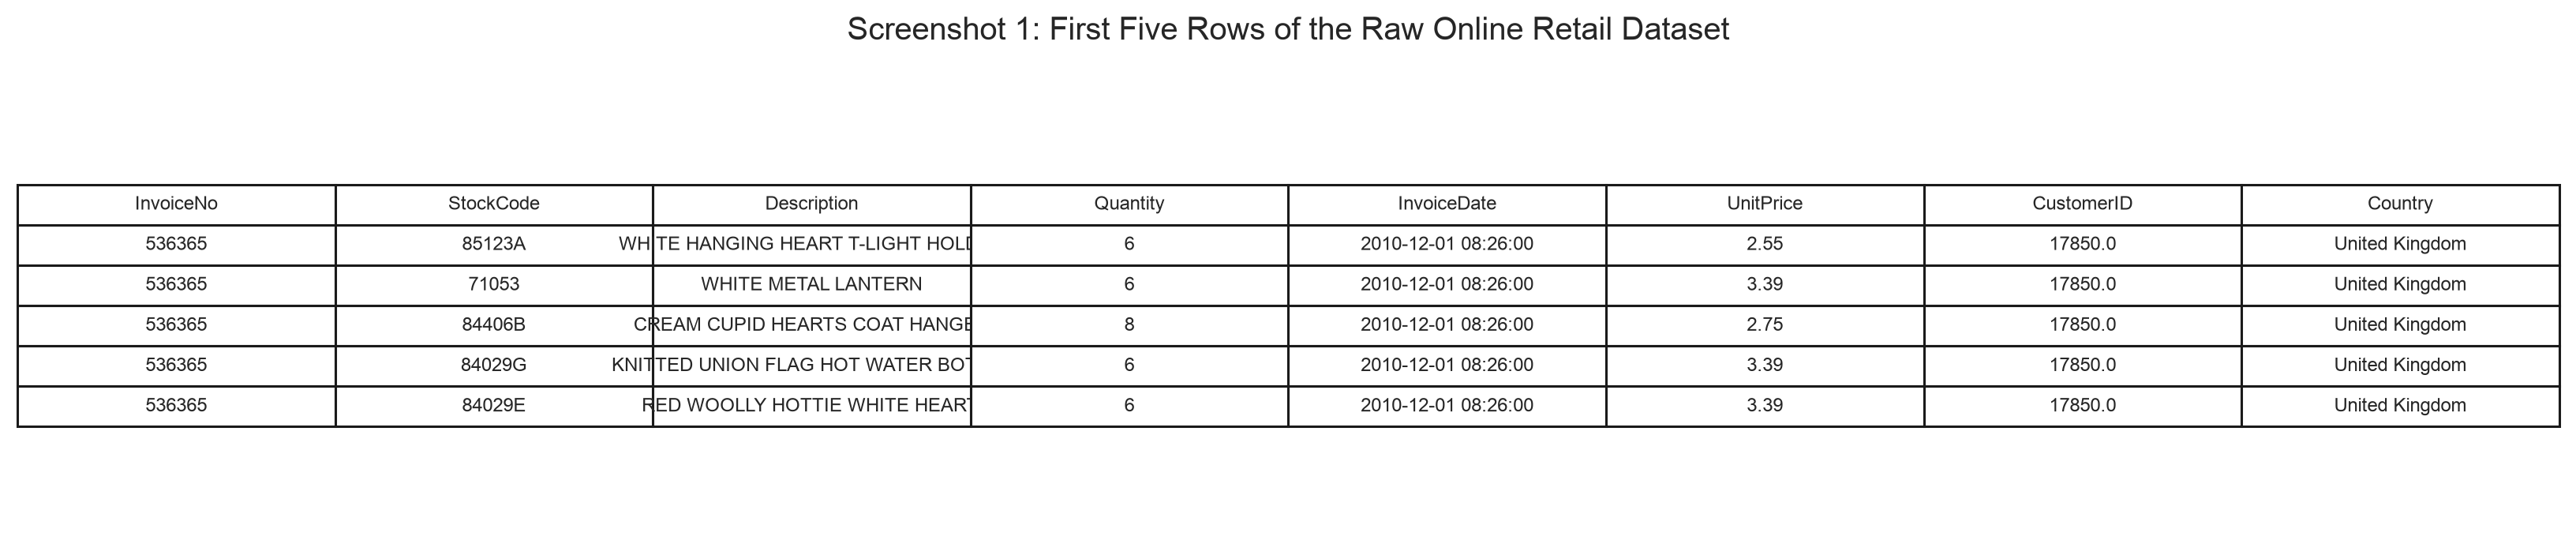

In [2]:
retail_raw = pd.read_excel(DATA_PATH)
print(f"Raw dataset shape: {retail_raw.shape[0]:,} rows and {retail_raw.shape[1]} columns")
display(retail_raw.head())

head_image = save_table(
    retail_raw.head(),
    "01_dataset_first_five_rows.png",
    "Screenshot 1: First Five Rows of the Raw Online Retail Dataset",
    max_rows=5,
)
display(Image(filename=str(head_image)))

## Step 2: Data visualization

Visualizations use positive sales records with a known customer identifier after basic cleaning, since cancellation rows and zero-value lines would distort revenue patterns. The original source remains unchanged in `data/raw`, while the cleaned analysis file is written later in the notebook.

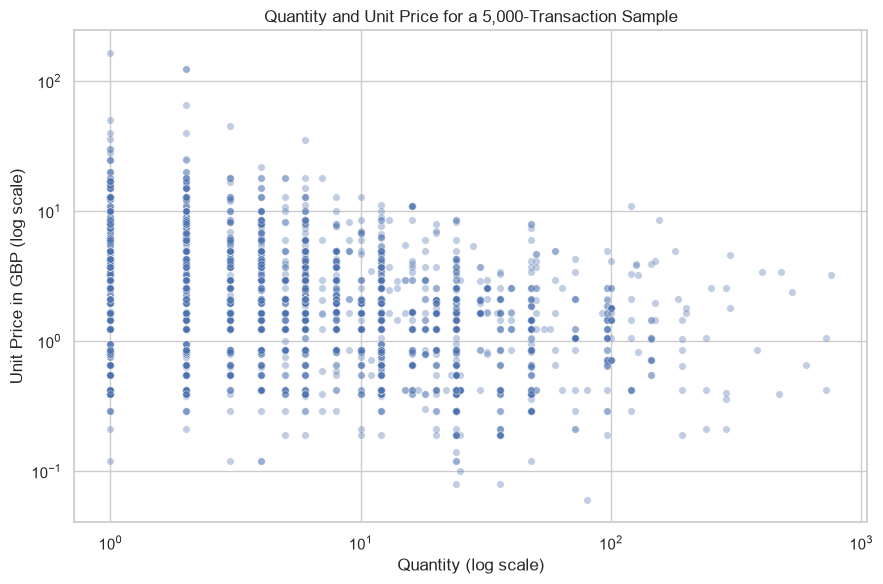

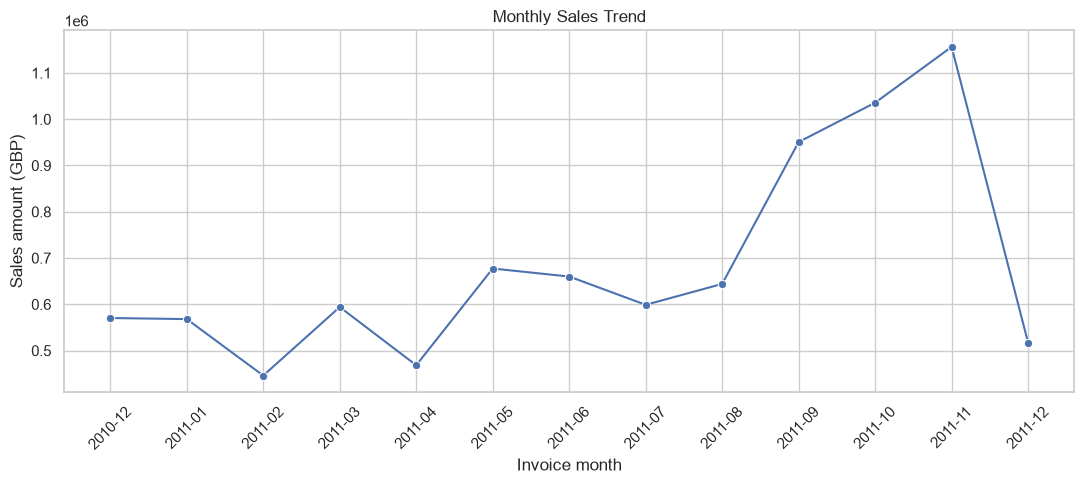

Scatter plot insight: smaller quantities account for most transactions, while high-price items are comparatively uncommon. Monthly sales vary across the year and rise sharply near the 2011 holiday period.


In [3]:
visual_data = retail_raw.dropna(subset=["CustomerID"]).copy()
visual_data["Description"] = visual_data["Description"].fillna("Unknown product description")
visual_data = visual_data.drop_duplicates()
visual_data = visual_data[
    (visual_data["Quantity"] > 0) & (visual_data["UnitPrice"] > 0)
].copy()
visual_data["SalesAmount"] = visual_data["Quantity"] * visual_data["UnitPrice"]
visual_data["Month"] = visual_data["InvoiceDate"].dt.to_period("M").astype(str)

scatter_sample = visual_data.sample(n=5_000, random_state=42)
figure, axis = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=scatter_sample,
    x="Quantity",
    y="UnitPrice",
    alpha=0.35,
    s=28,
    ax=axis,
)
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_title("Quantity and Unit Price for a 5,000-Transaction Sample")
axis.set_xlabel("Quantity (log scale)")
axis.set_ylabel("Unit Price in GBP (log scale)")
figure.tight_layout()
scatter_file = SCREENSHOT_PATH / "02_scatter_quantity_unit_price.png"
figure.savefig(scatter_file, dpi=300, bbox_inches="tight")
plt.show()

monthly_sales = visual_data.groupby("Month", as_index=False)["SalesAmount"].sum()
figure, axis = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly_sales, x="Month", y="SalesAmount", marker="o", ax=axis)
axis.set_title("Monthly Sales Trend")
axis.set_xlabel("Invoice month")
axis.set_ylabel("Sales amount (GBP)")
axis.tick_params(axis="x", rotation=45)
figure.tight_layout()
line_file = SCREENSHOT_PATH / "03_line_monthly_sales.png"
figure.savefig(line_file, dpi=300, bbox_inches="tight")
plt.show()

print(
    "Scatter plot insight: smaller quantities account for most transactions, while "
    "high-price items are comparatively uncommon. Monthly sales vary across the year "
    "and rise sharply near the 2011 holiday period."
)

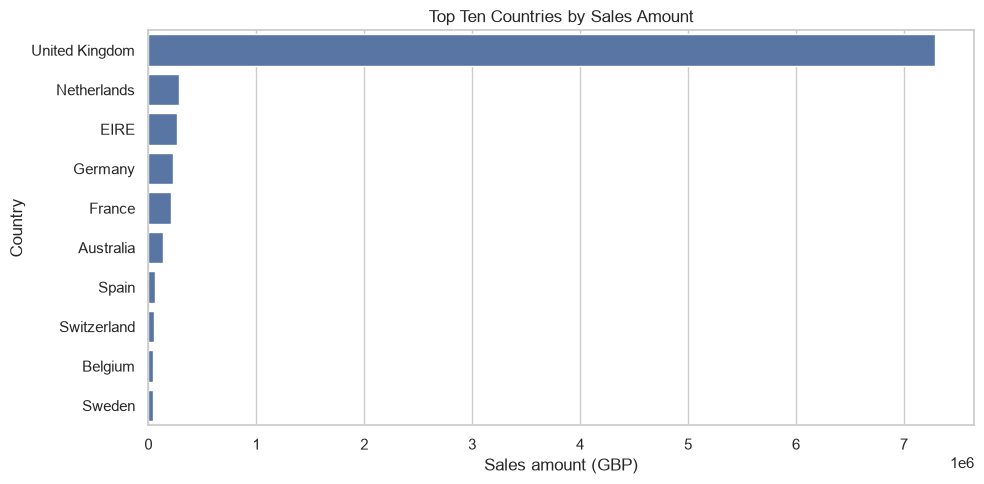

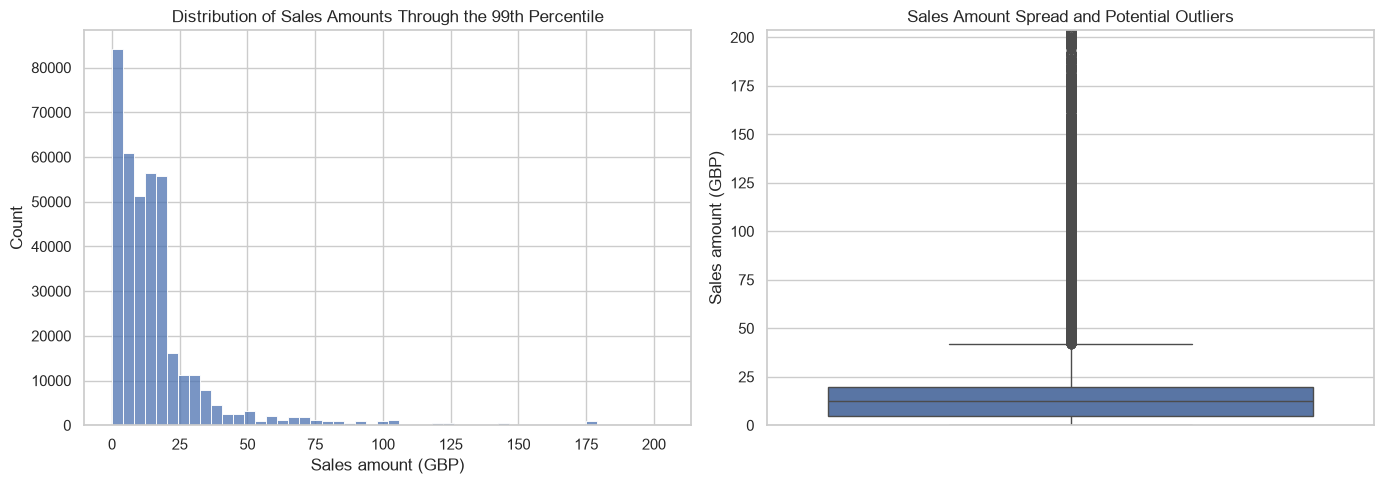

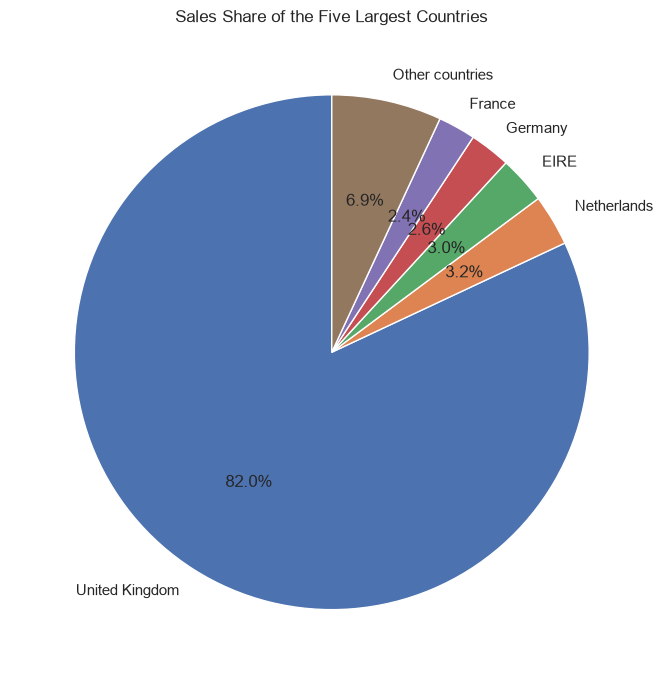

The United Kingdom contributes most sales because it contains most transactions. The histogram is right-skewed, and the box plot shows a small number of large sales lines that need outlier review rather than automatic deletion.


In [4]:
top_countries = (
    visual_data.groupby("Country", as_index=False)["SalesAmount"]
    .sum()
    .nlargest(10, "SalesAmount")
)
figure, axis = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_countries, y="Country", x="SalesAmount", ax=axis)
axis.set_title("Top Ten Countries by Sales Amount")
axis.set_xlabel("Sales amount (GBP)")
axis.set_ylabel("Country")
figure.tight_layout()
bar_file = SCREENSHOT_PATH / "04_bar_top_countries.png"
figure.savefig(bar_file, dpi=300, bbox_inches="tight")
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
sales_cap = visual_data["SalesAmount"].quantile(0.99)
sns.histplot(
    visual_data.loc[visual_data["SalesAmount"] <= sales_cap, "SalesAmount"],
    bins=50,
    ax=axes[0],
)
axes[0].set_title("Distribution of Sales Amounts Through the 99th Percentile")
axes[0].set_xlabel("Sales amount (GBP)")

sns.boxplot(y=visual_data["SalesAmount"], ax=axes[1])
axes[1].set_title("Sales Amount Spread and Potential Outliers")
axes[1].set_ylabel("Sales amount (GBP)")
axes[1].set_ylim(0, sales_cap)
figure.tight_layout()
distribution_file = SCREENSHOT_PATH / "05_histogram_and_boxplot_sales.png"
figure.savefig(distribution_file, dpi=300, bbox_inches="tight")
plt.show()

country_share = visual_data.groupby("Country")["SalesAmount"].sum().sort_values(ascending=False)
pie_data = pd.concat(
    [country_share.head(5), pd.Series({"Other countries": country_share.iloc[5:].sum()})]
)
figure, axis = plt.subplots(figsize=(8, 7))
axis.pie(pie_data, labels=pie_data.index, autopct="%1.1f%%", startangle=90)
axis.set_title("Sales Share of the Five Largest Countries")
figure.tight_layout()
pie_file = SCREENSHOT_PATH / "06_pie_country_sales_share.png"
figure.savefig(pie_file, dpi=300, bbox_inches="tight")
plt.show()

print(
    "The United Kingdom contributes most sales because it contains most transactions. "
    "The histogram is right-skewed, and the box plot shows a small number of large "
    "sales lines that need outlier review rather than automatic deletion."
)

## Step 3: Data preprocessing

,Before handling,After handling
InvoiceNo,0,0
StockCode,0,0
Description,1454,0
Quantity,0,0
InvoiceDate,0,0
UnitPrice,0,0
CustomerID,135080,0
Country,0,0


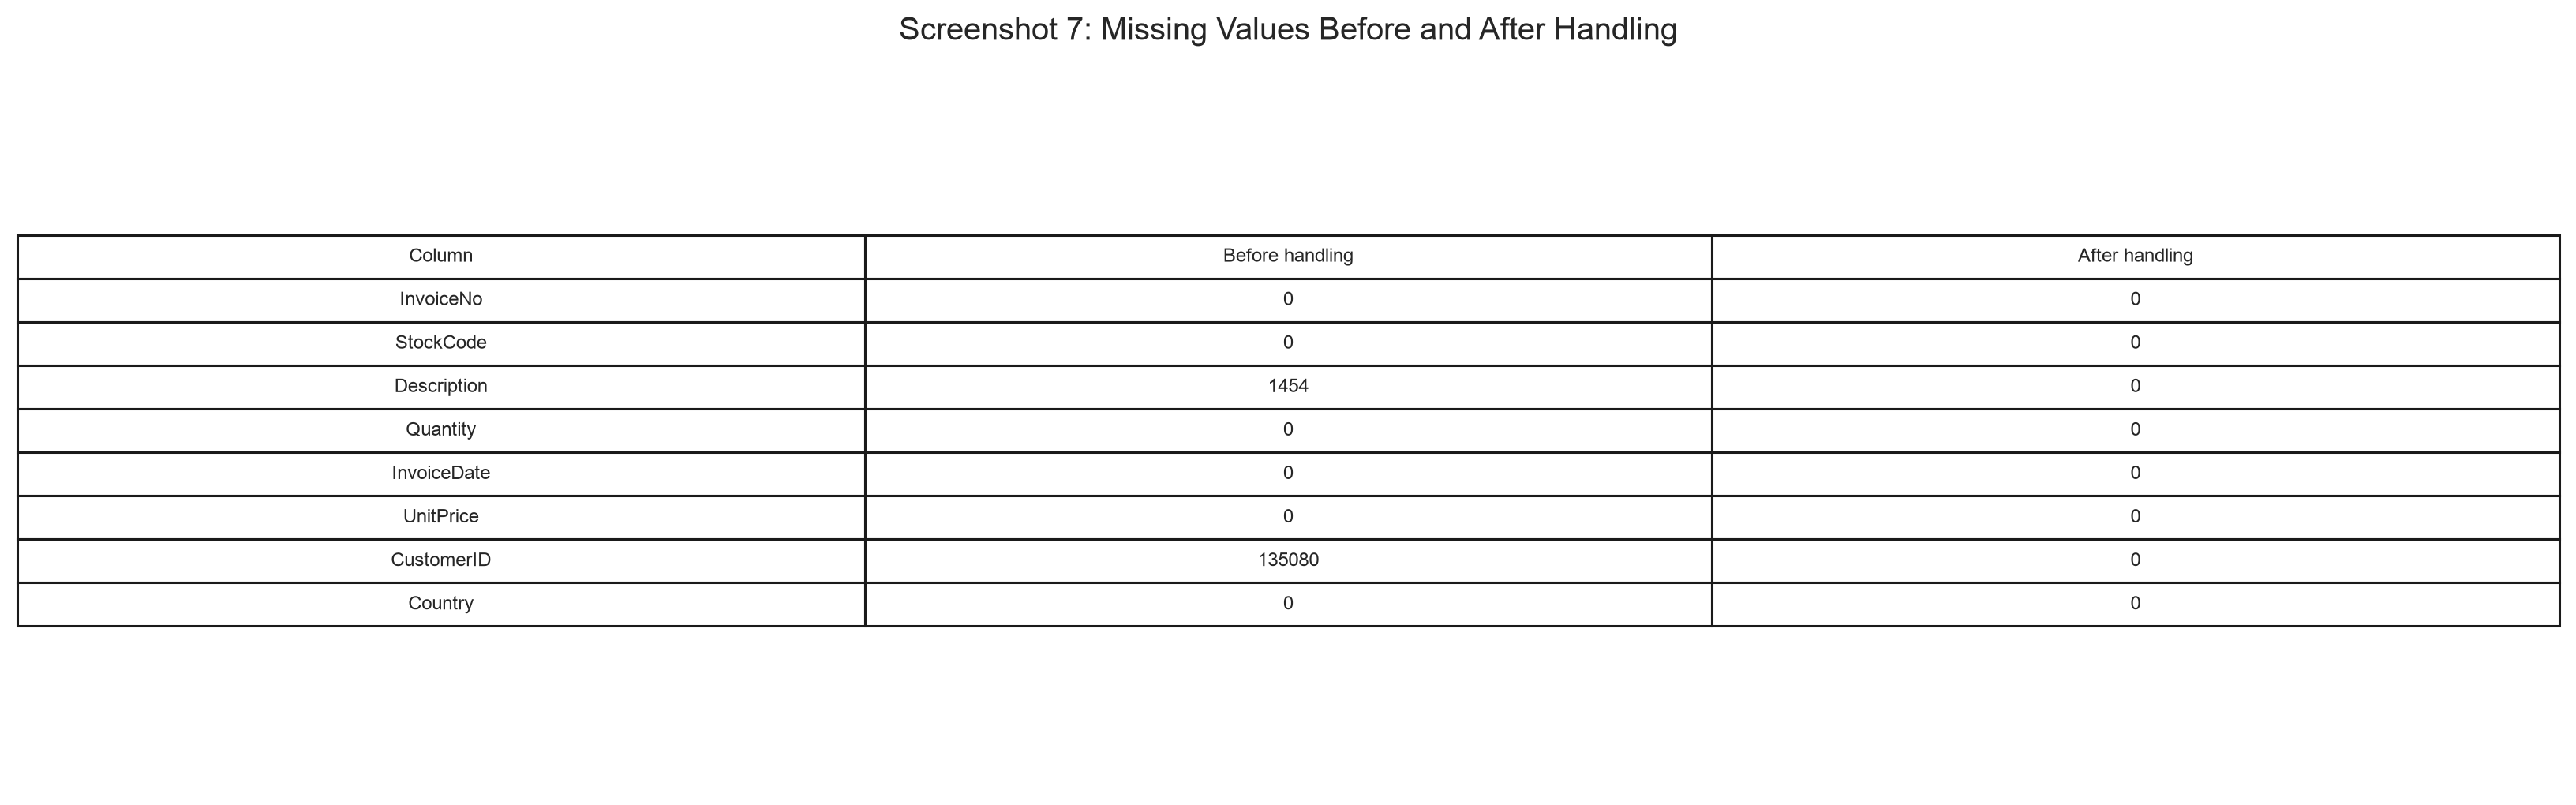

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


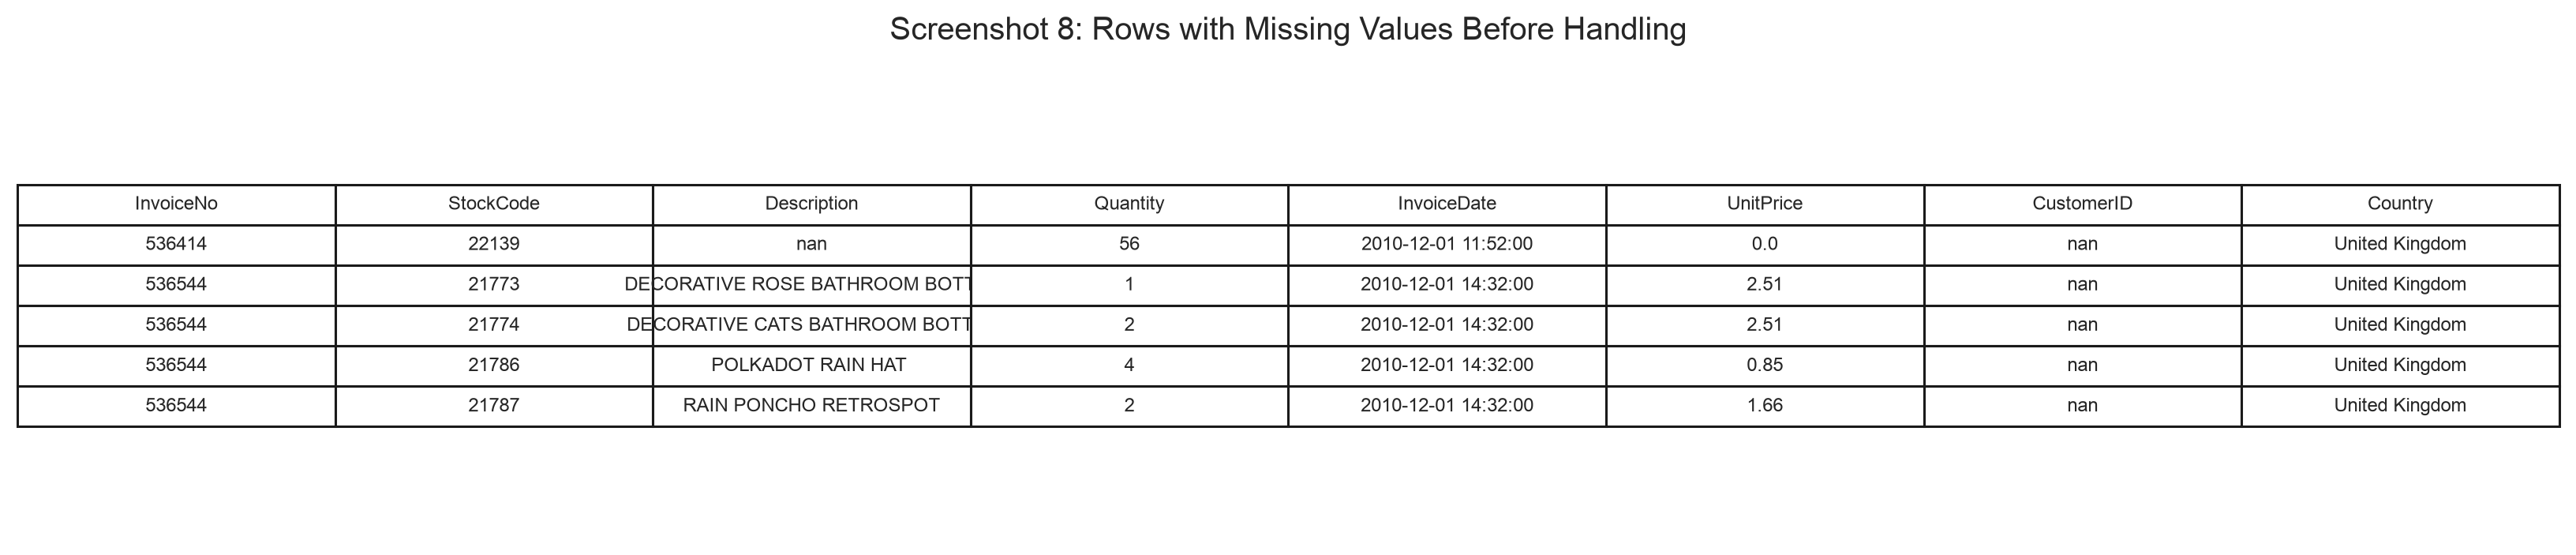

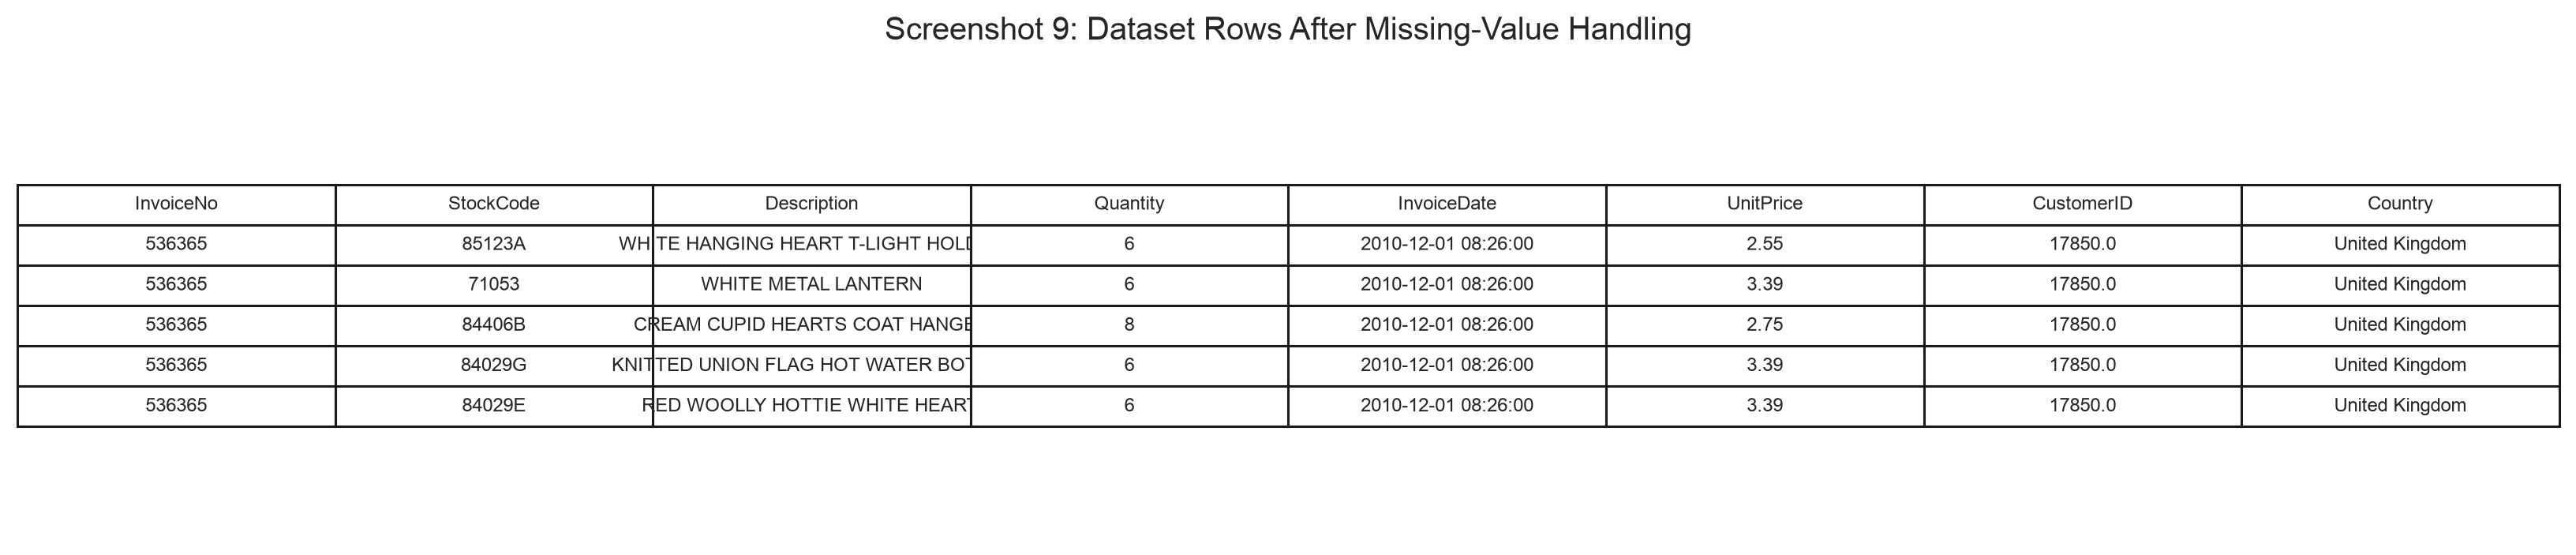

Description values missing in the source were filled with a clear label. Rows without CustomerID were removed because they cannot support customer-level retail analysis. Rows changed from 541,909 to 406,829.


In [5]:
missing_before = retail_raw.isna().sum().rename("Before handling")
working = retail_raw.copy()
working["Description"] = working["Description"].fillna("Unknown product description")
working = working.dropna(subset=["CustomerID"]).copy()
missing_after = working.isna().sum().rename("After handling")

missing_comparison = pd.concat([missing_before, missing_after], axis=1)
display(missing_comparison)
missing_image = save_table(
    missing_comparison.reset_index().rename(columns={"index": "Column"}),
    "07_missing_values_before_after.png",
    "Screenshot 7: Missing Values Before and After Handling",
    max_rows=8,
)
display(Image(filename=str(missing_image)))
missing_rows_before = retail_raw.loc[
    retail_raw["CustomerID"].isna() | retail_raw["Description"].isna()
]
display(missing_rows_before.head())
display(working.head())
before_missing_rows_image = save_table(
    missing_rows_before,
    "08_rows_before_missing_value_handling.png",
    "Screenshot 8: Rows with Missing Values Before Handling",
    max_rows=5,
)
after_missing_rows_image = save_table(
    working,
    "09_rows_after_missing_value_handling.png",
    "Screenshot 9: Dataset Rows After Missing-Value Handling",
    max_rows=5,
)
display(Image(filename=str(before_missing_rows_image)))
display(Image(filename=str(after_missing_rows_image)))

print(
    f"Description values missing in the source were filled with a clear label. "
    f"Rows without CustomerID were removed because they cannot support customer-level "
    f"retail analysis. Rows changed from {len(retail_raw):,} to {len(working):,}."
)

,Q1,Q3,IQR,Lower bound,Upper bound,Identified sales-amount outliers
0,4.95,19.80,14.85,-17.32,42.07,31231


,InvoiceNo,Description,Quantity,UnitPrice,SalesAmount
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08
26,536370,ALARM CLOCK BAKELIKE PINK,24,3.75,90.00
27,536370,ALARM CLOCK BAKELIKE RED,24,3.75,90.00
28,536370,ALARM CLOCK BAKELIKE GREEN,12,3.75,45.00
33,536370,SET/2 RED RETROSPOT TEA TOWELS,18,2.95,53.10


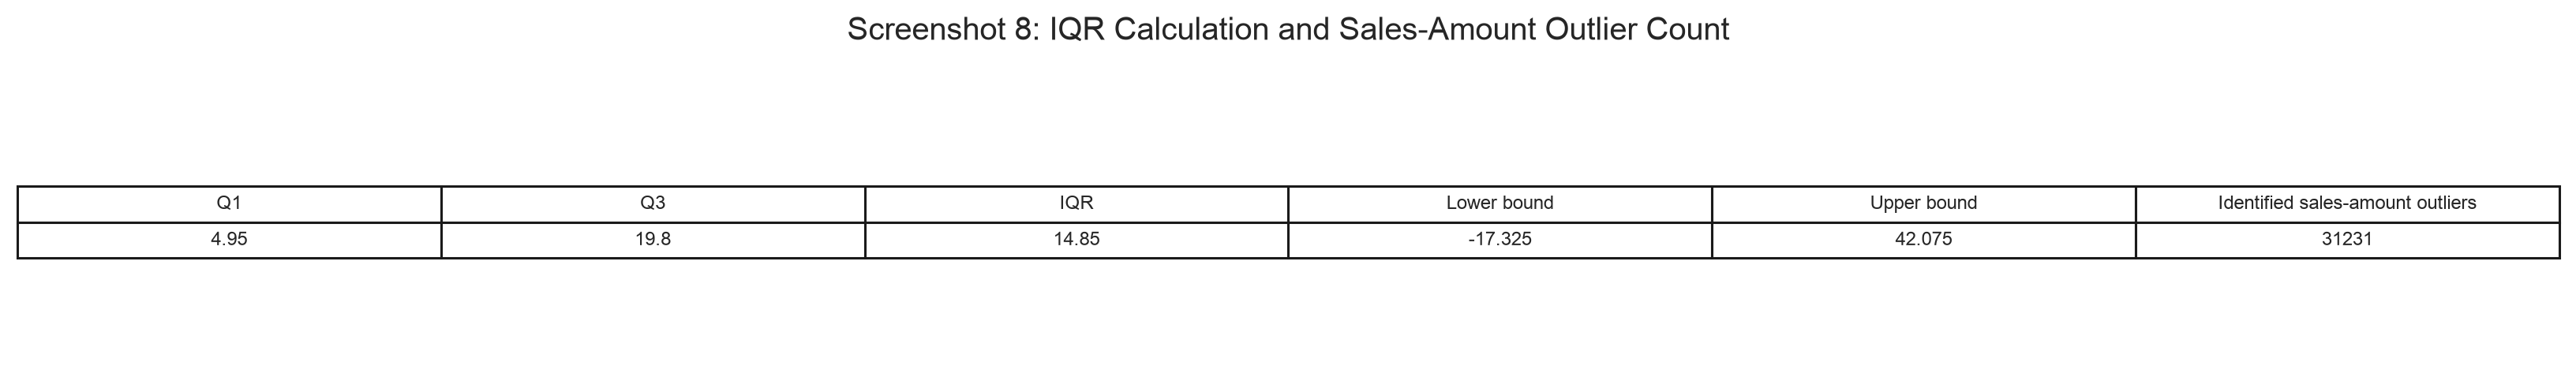

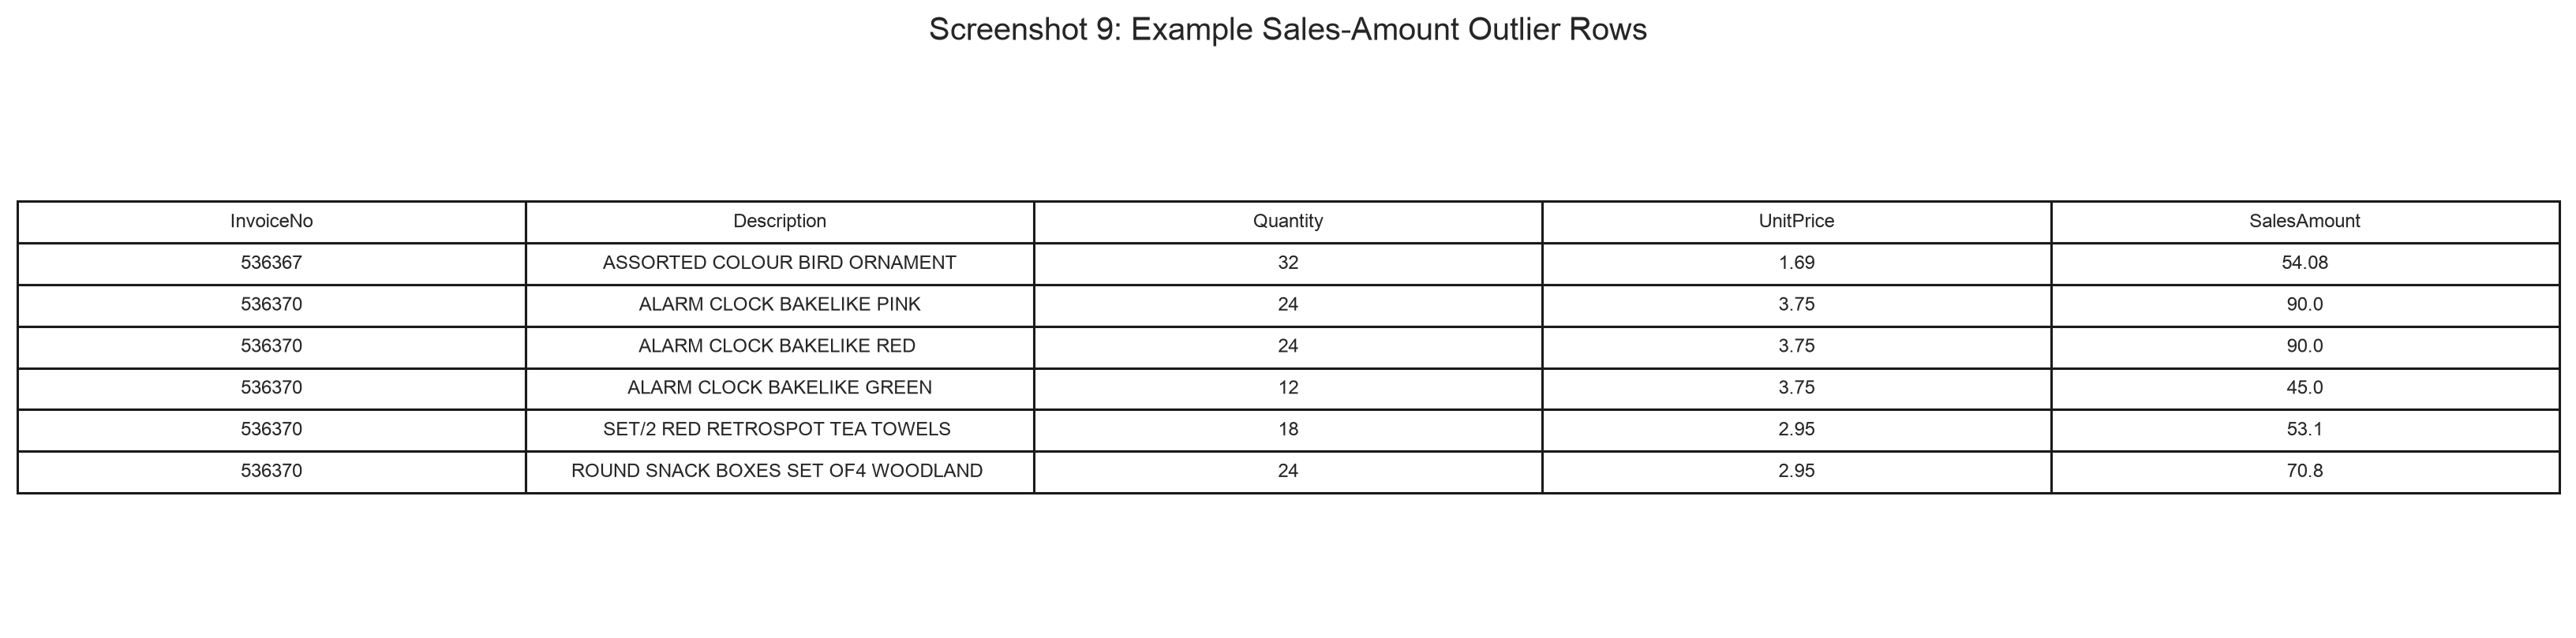

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34


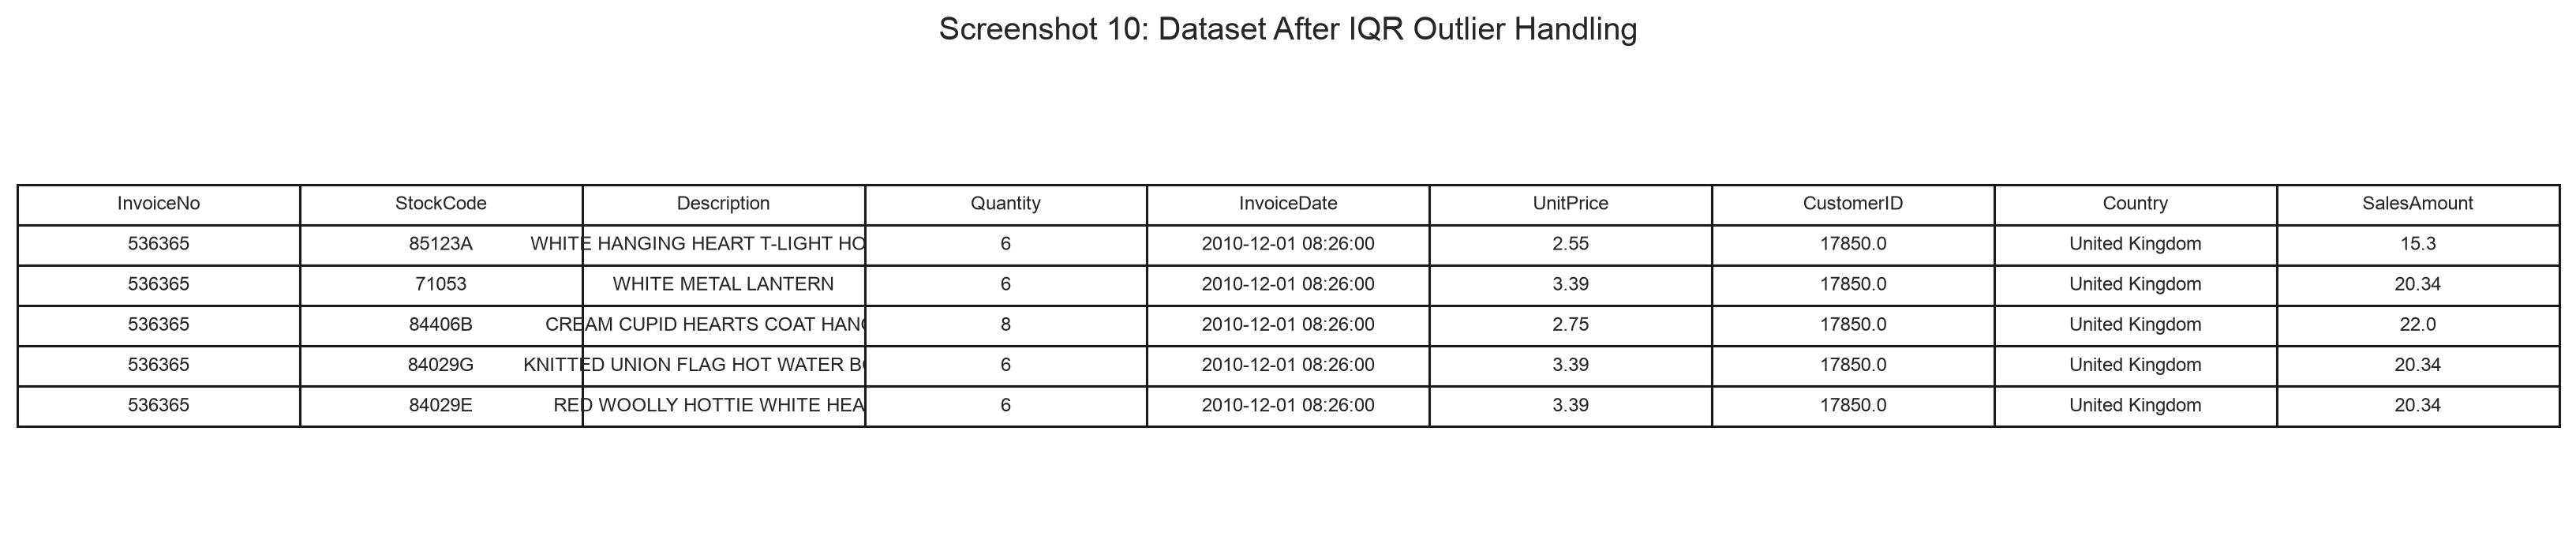

Duplicate rows removed: 5,225
Cancellation, return, or zero-value rows removed: 8,912
IQR outliers removed: 31,231
Rows after outlier handling: 361,461


In [6]:
duplicate_count = int(working.duplicated().sum())
working = working.drop_duplicates().copy()
non_sales_count = int(((working["Quantity"] <= 0) | (working["UnitPrice"] <= 0)).sum())
working = working[(working["Quantity"] > 0) & (working["UnitPrice"] > 0)].copy()
working["SalesAmount"] = working["Quantity"] * working["UnitPrice"]

q1 = working["SalesAmount"].quantile(0.25)
q3 = working["SalesAmount"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (working["SalesAmount"] < lower_bound) | (working["SalesAmount"] > upper_bound)
outliers = working.loc[outlier_mask].copy()

iqr_results = pd.DataFrame(
    {
        "Q1": [q1],
        "Q3": [q3],
        "IQR": [iqr],
        "Lower bound": [lower_bound],
        "Upper bound": [upper_bound],
        "Identified sales-amount outliers": [len(outliers)],
    }
)
display(iqr_results)
display(outliers[["InvoiceNo", "Description", "Quantity", "UnitPrice", "SalesAmount"]].head())
iqr_image = save_table(
    iqr_results,
    "08_iqr_and_identified_outliers.png",
    "Screenshot 8: IQR Calculation and Sales-Amount Outlier Count",
)
display(Image(filename=str(iqr_image)))

outlier_preview = save_table(
    outliers[["InvoiceNo", "Description", "Quantity", "UnitPrice", "SalesAmount"]],
    "09_identified_outlier_rows.png",
    "Screenshot 9: Example Sales-Amount Outlier Rows",
    max_rows=6,
)
display(Image(filename=str(outlier_preview)))

cleaned = working.loc[~outlier_mask].copy()
display(cleaned.head())
after_outlier_image = save_table(
    cleaned,
    "10_dataset_after_outlier_handling.png",
    "Screenshot 10: Dataset After IQR Outlier Handling",
    max_rows=5,
)
display(Image(filename=str(after_outlier_image)))
print(f"Duplicate rows removed: {duplicate_count:,}")
print(f"Cancellation, return, or zero-value rows removed: {non_sales_count:,}")
print(f"IQR outliers removed: {len(outliers):,}")
print(f"Rows after outlier handling: {len(cleaned):,}")

,Rows,Columns,Data size,Stage
0,361461,9,Positive sales after cleaning,Before reduction
1,36146,5,10% reproducible sample with identifier fields...,After reduction


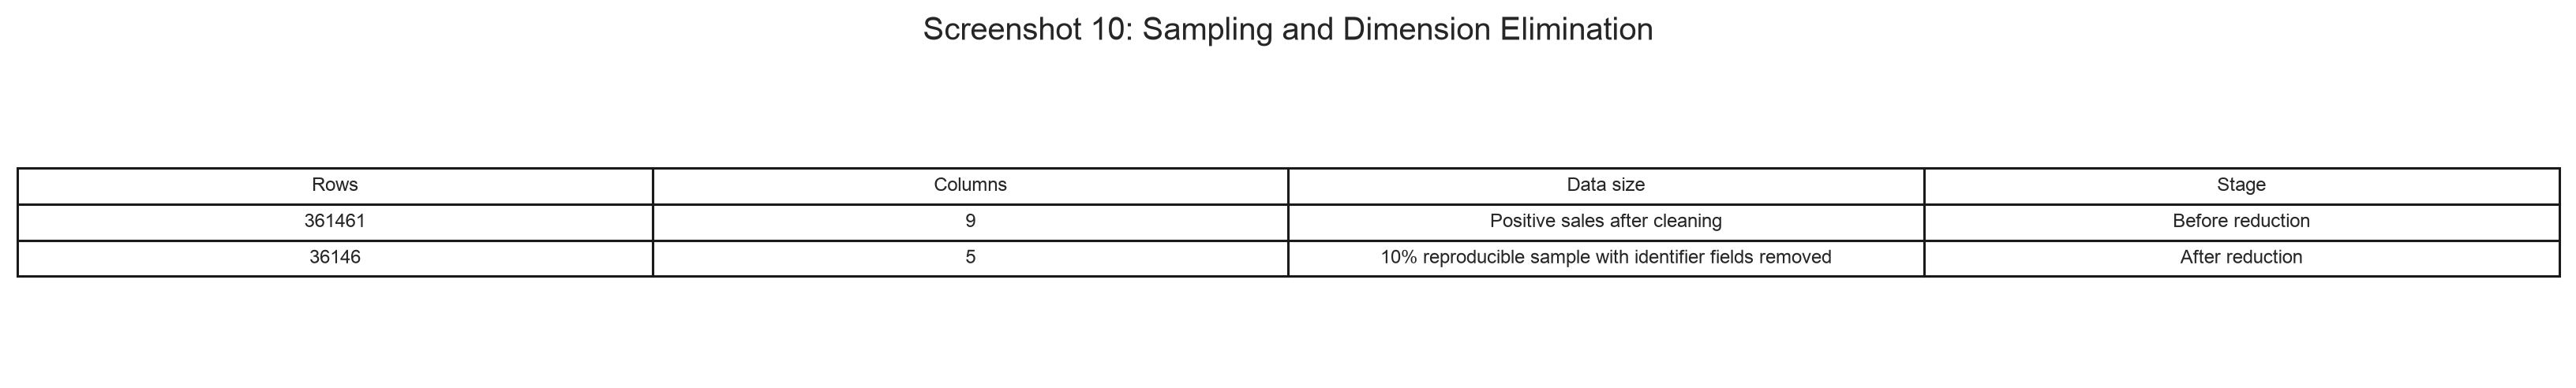

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34


,Quantity,InvoiceDate,UnitPrice,Country,SalesAmount
382576,20,2011-10-06 16:54:00,1.95,United Kingdom,39.00
523440,2,2011-12-04 13:59:00,1.45,United Kingdom,2.90
301807,1,2011-08-15 14:35:00,3.75,United Kingdom,3.75
144654,1,2011-04-04 12:42:00,1.65,United Kingdom,1.65
134035,1,2011-03-25 14:45:00,2.95,United Kingdom,2.95


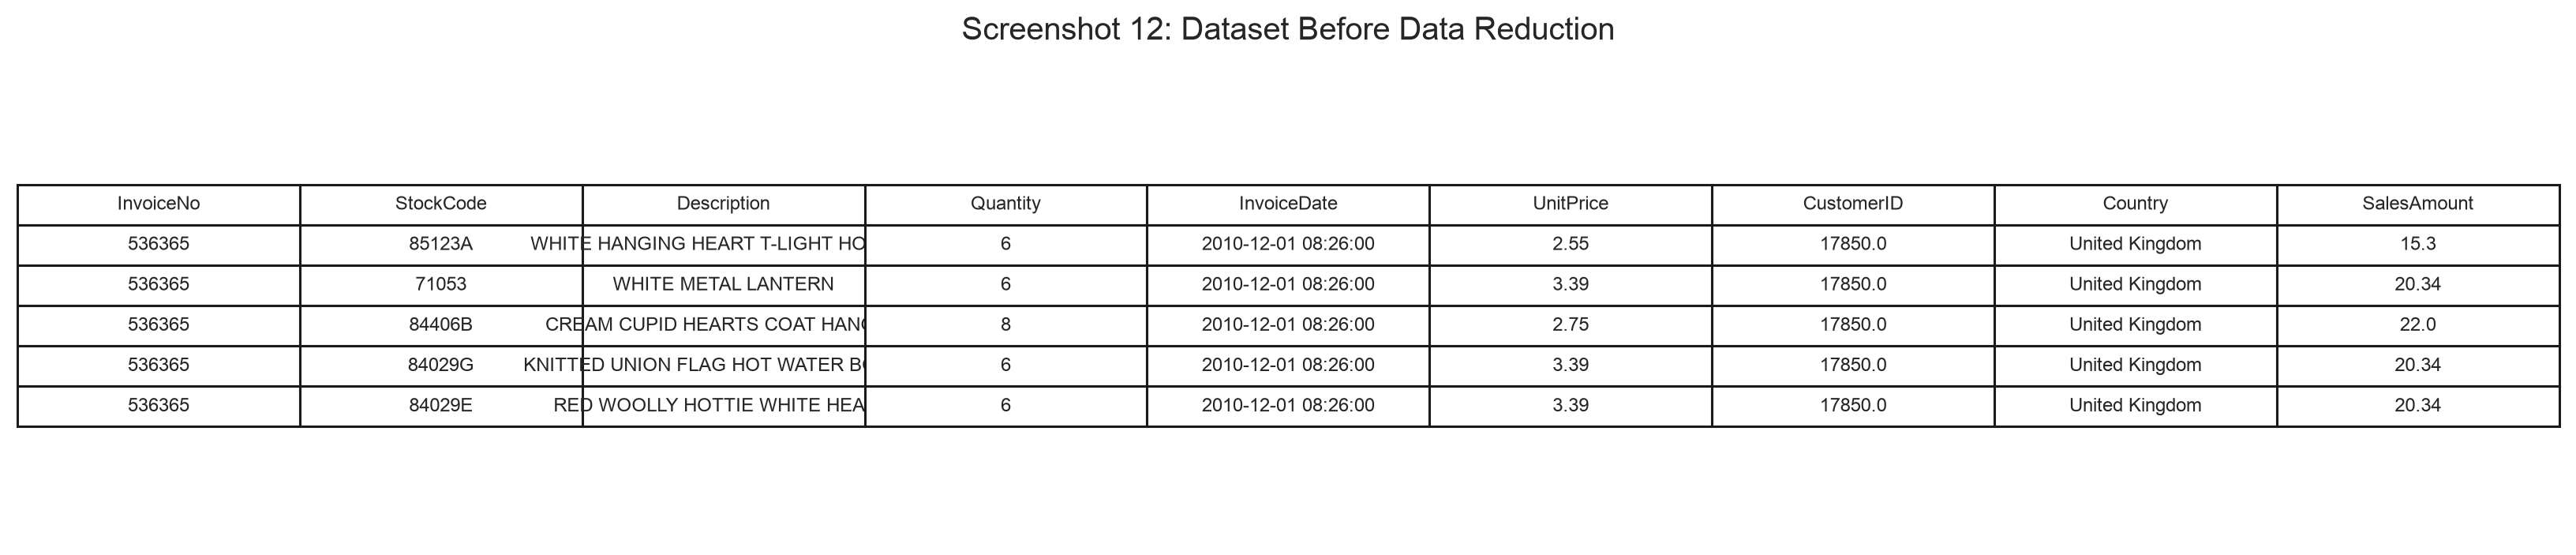

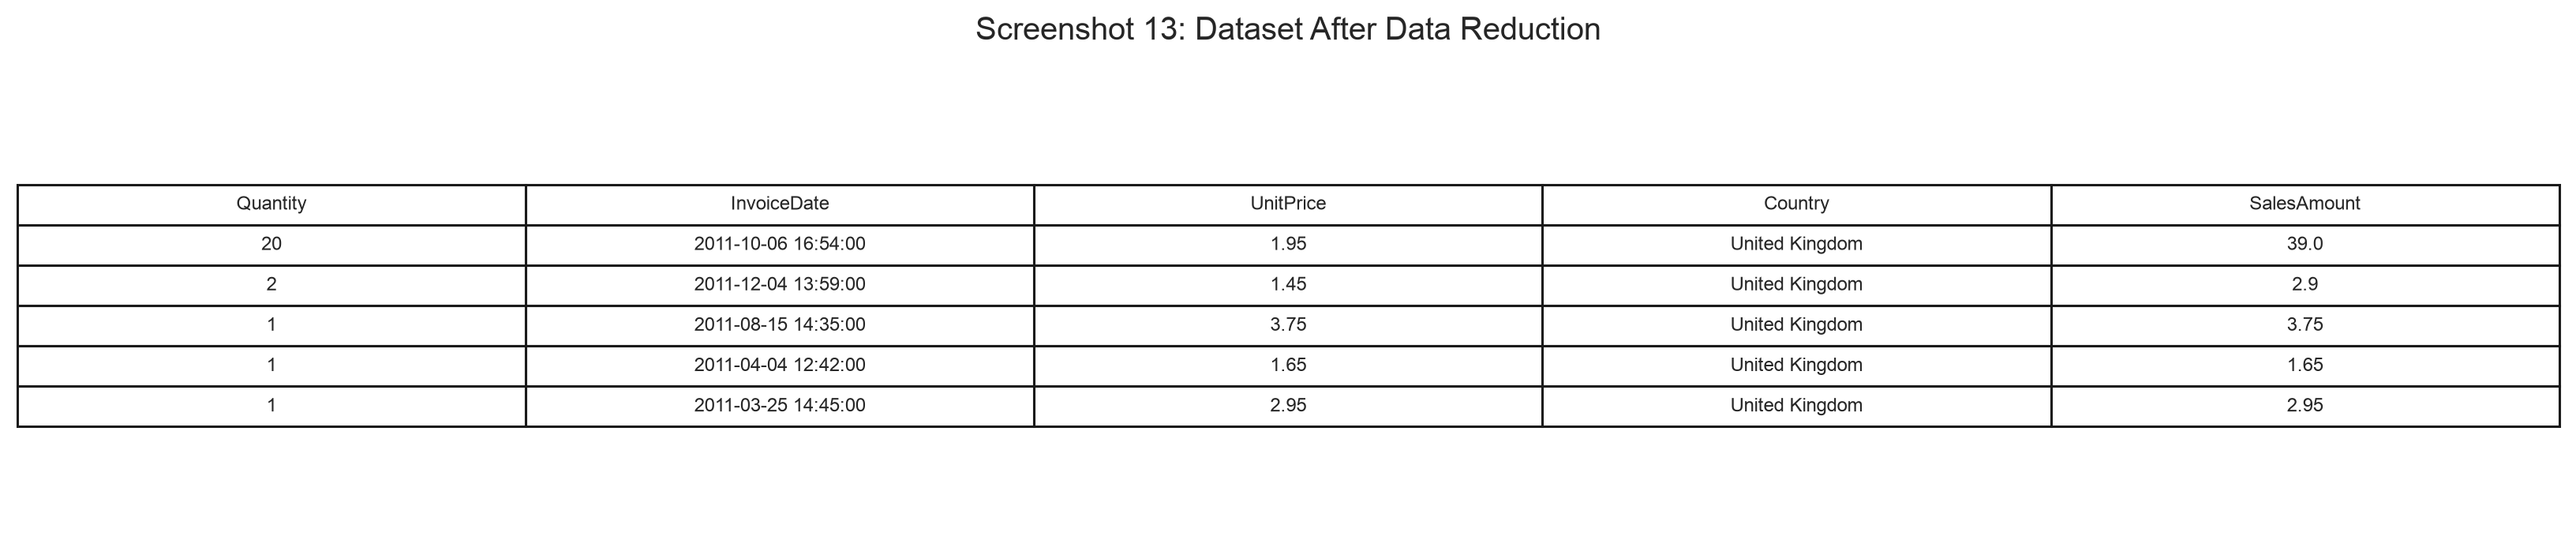

In [7]:
before_reduction = pd.DataFrame(
    {
        "Rows": [len(cleaned)],
        "Columns": [cleaned.shape[1]],
        "Data size": ["Positive sales after cleaning"],
    }
)
sampled = cleaned.sample(frac=0.10, random_state=42).copy()
reduced = sampled.drop(columns=["InvoiceNo", "StockCode", "Description", "CustomerID"]).copy()
after_reduction = pd.DataFrame(
    {
        "Rows": [len(reduced)],
        "Columns": [reduced.shape[1]],
        "Data size": ["10% reproducible sample with identifier fields removed"],
    }
)
reduction_summary = pd.concat(
    [before_reduction.assign(Stage="Before reduction"), after_reduction.assign(Stage="After reduction")],
    ignore_index=True,
)
display(reduction_summary)
reduction_image = save_table(
    reduction_summary,
    "10_data_reduction_before_after.png",
    "Screenshot 10: Sampling and Dimension Elimination",
    max_rows=2,
)
display(Image(filename=str(reduction_image)))
display(cleaned.head())
display(reduced.head())
before_reduction_image = save_table(
    cleaned,
    "12_dataset_before_reduction.png",
    "Screenshot 12: Dataset Before Data Reduction",
    max_rows=5,
)
after_reduction_image = save_table(
    reduced,
    "13_dataset_after_reduction.png",
    "Screenshot 13: Dataset After Data Reduction",
    max_rows=5,
)
display(Image(filename=str(before_reduction_image)))
display(Image(filename=str(after_reduction_image)))

,Quantity,UnitPrice,SalesAmount,UnitPrice_MinMax,SalesAmount_MinMax,QuantityBand
382576,20,1.95,39.00,0.05,0.93,Large order
523440,2,1.45,2.90,0.04,0.07,Small order
301807,1,3.75,3.75,0.09,0.09,Single item
144654,1,1.65,1.65,0.04,0.04,Single item
134035,1,2.95,2.95,0.07,0.07,Single item
206279,2,7.50,15.00,0.19,0.36,Small order
243112,4,3.75,15.00,0.09,0.36,Small order
211126,1,4.95,4.95,0.12,0.12,Single item


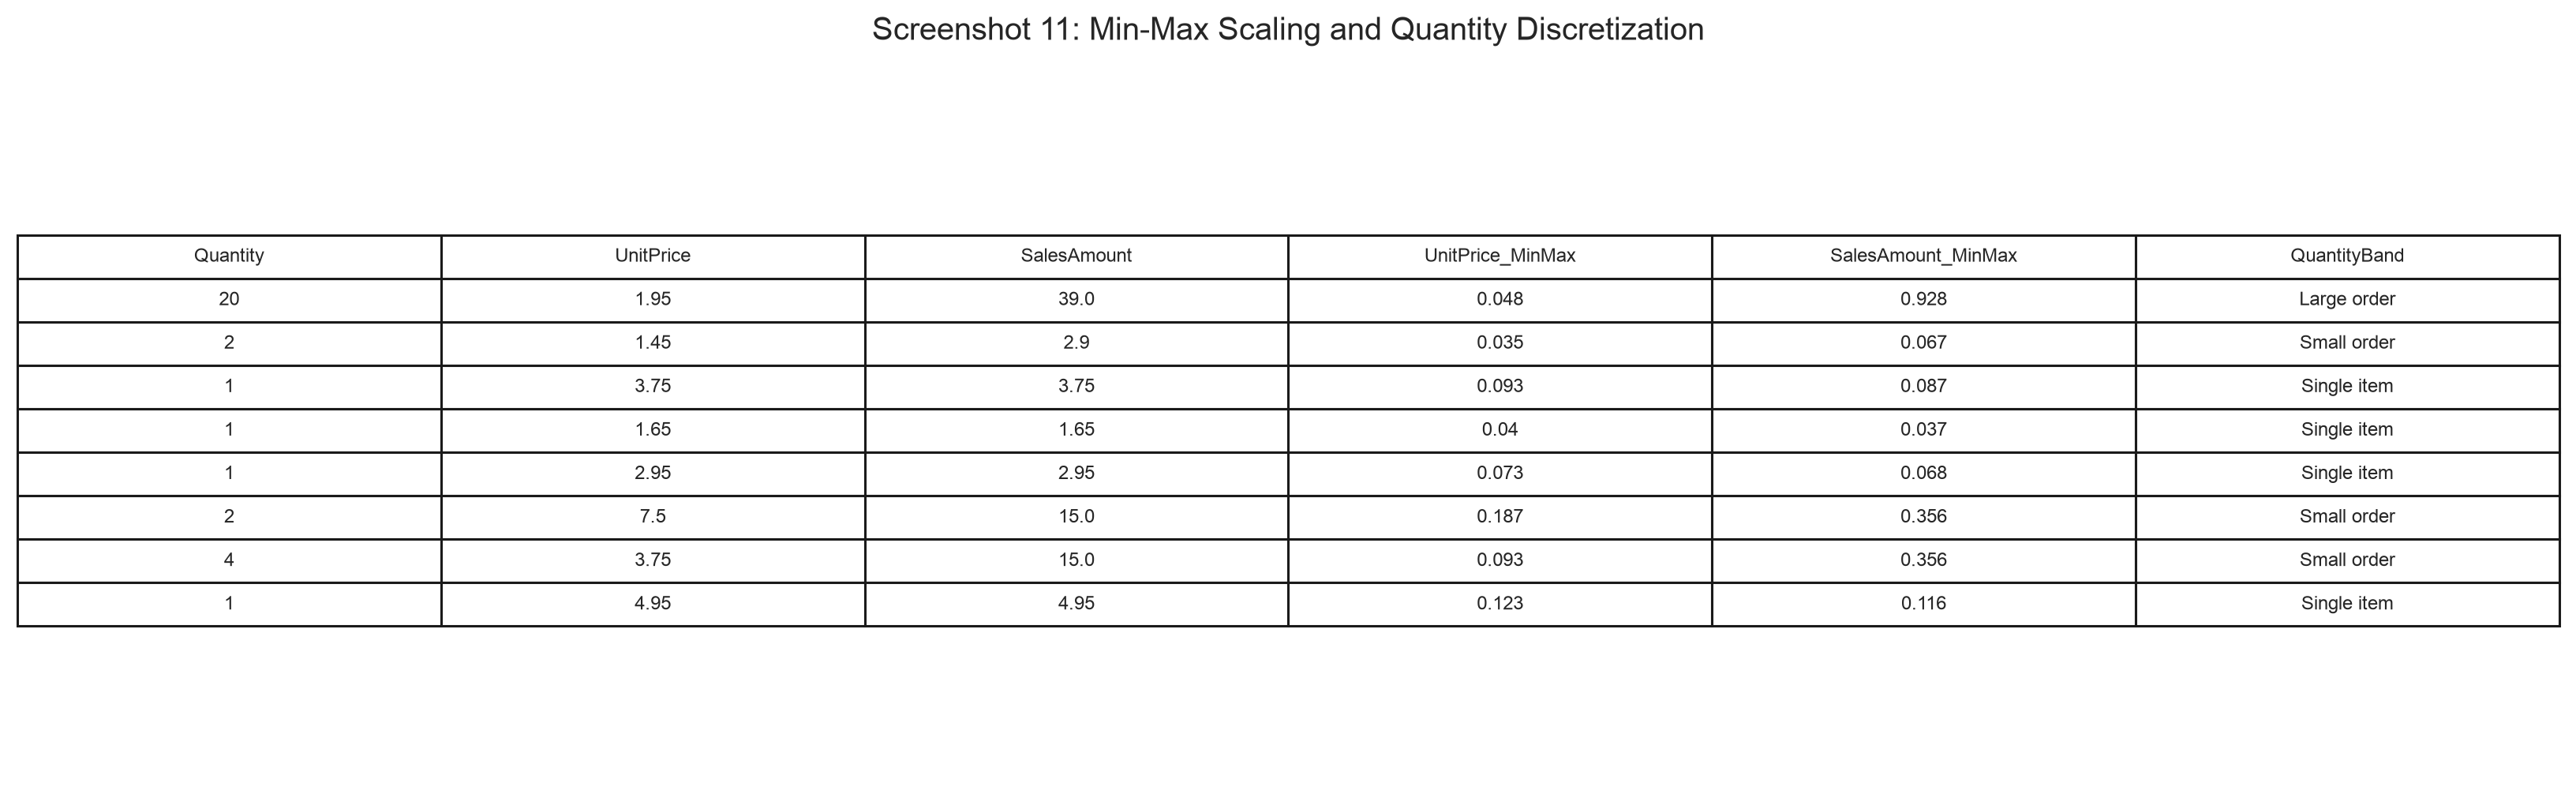

Final reduced file saved to data/processed/online_retail_lab_cleaned.csv


In [8]:
scale_columns = ["UnitPrice", "SalesAmount"]
scaler = MinMaxScaler()
reduced[[f"{column}_MinMax" for column in scale_columns]] = scaler.fit_transform(
    reduced[scale_columns]
)
reduced["QuantityBand"] = pd.cut(
    reduced["Quantity"],
    bins=[0, 1, 5, 12, np.inf],
    labels=["Single item", "Small order", "Medium order", "Large order"],
    include_lowest=True,
)

scaling_view = reduced[
    ["Quantity", "UnitPrice", "SalesAmount", "UnitPrice_MinMax", "SalesAmount_MinMax", "QuantityBand"]
].head(8)
display(scaling_view)
scaling_image = save_table(
    scaling_view,
    "11_scaling_and_discretization.png",
    "Screenshot 11: Min-Max Scaling and Quantity Discretization",
    max_rows=8,
)
display(Image(filename=str(scaling_image)))

reduced.to_csv(PROCESSED_PATH, index=False)
print(f"Final reduced file saved to {PROCESSED_PATH}")

## Step 4: Statistical analysis

DataFrame information
<class 'pandas.DataFrame'>
Index: 36146 entries, 382576 to 340458
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Quantity            36146 non-null  int64         
 1   InvoiceDate         36146 non-null  datetime64[us]
 2   UnitPrice           36146 non-null  float64       
 3   Country             36146 non-null  str           
 4   SalesAmount         36146 non-null  float64       
 5   UnitPrice_MinMax    36146 non-null  float64       
 6   SalesAmount_MinMax  36146 non-null  float64       
 7   QuantityBand        36146 non-null  category      
dtypes: category(1), datetime64[us](1), float64(4), int64(1), str(1)
memory usage: 2.2 MB


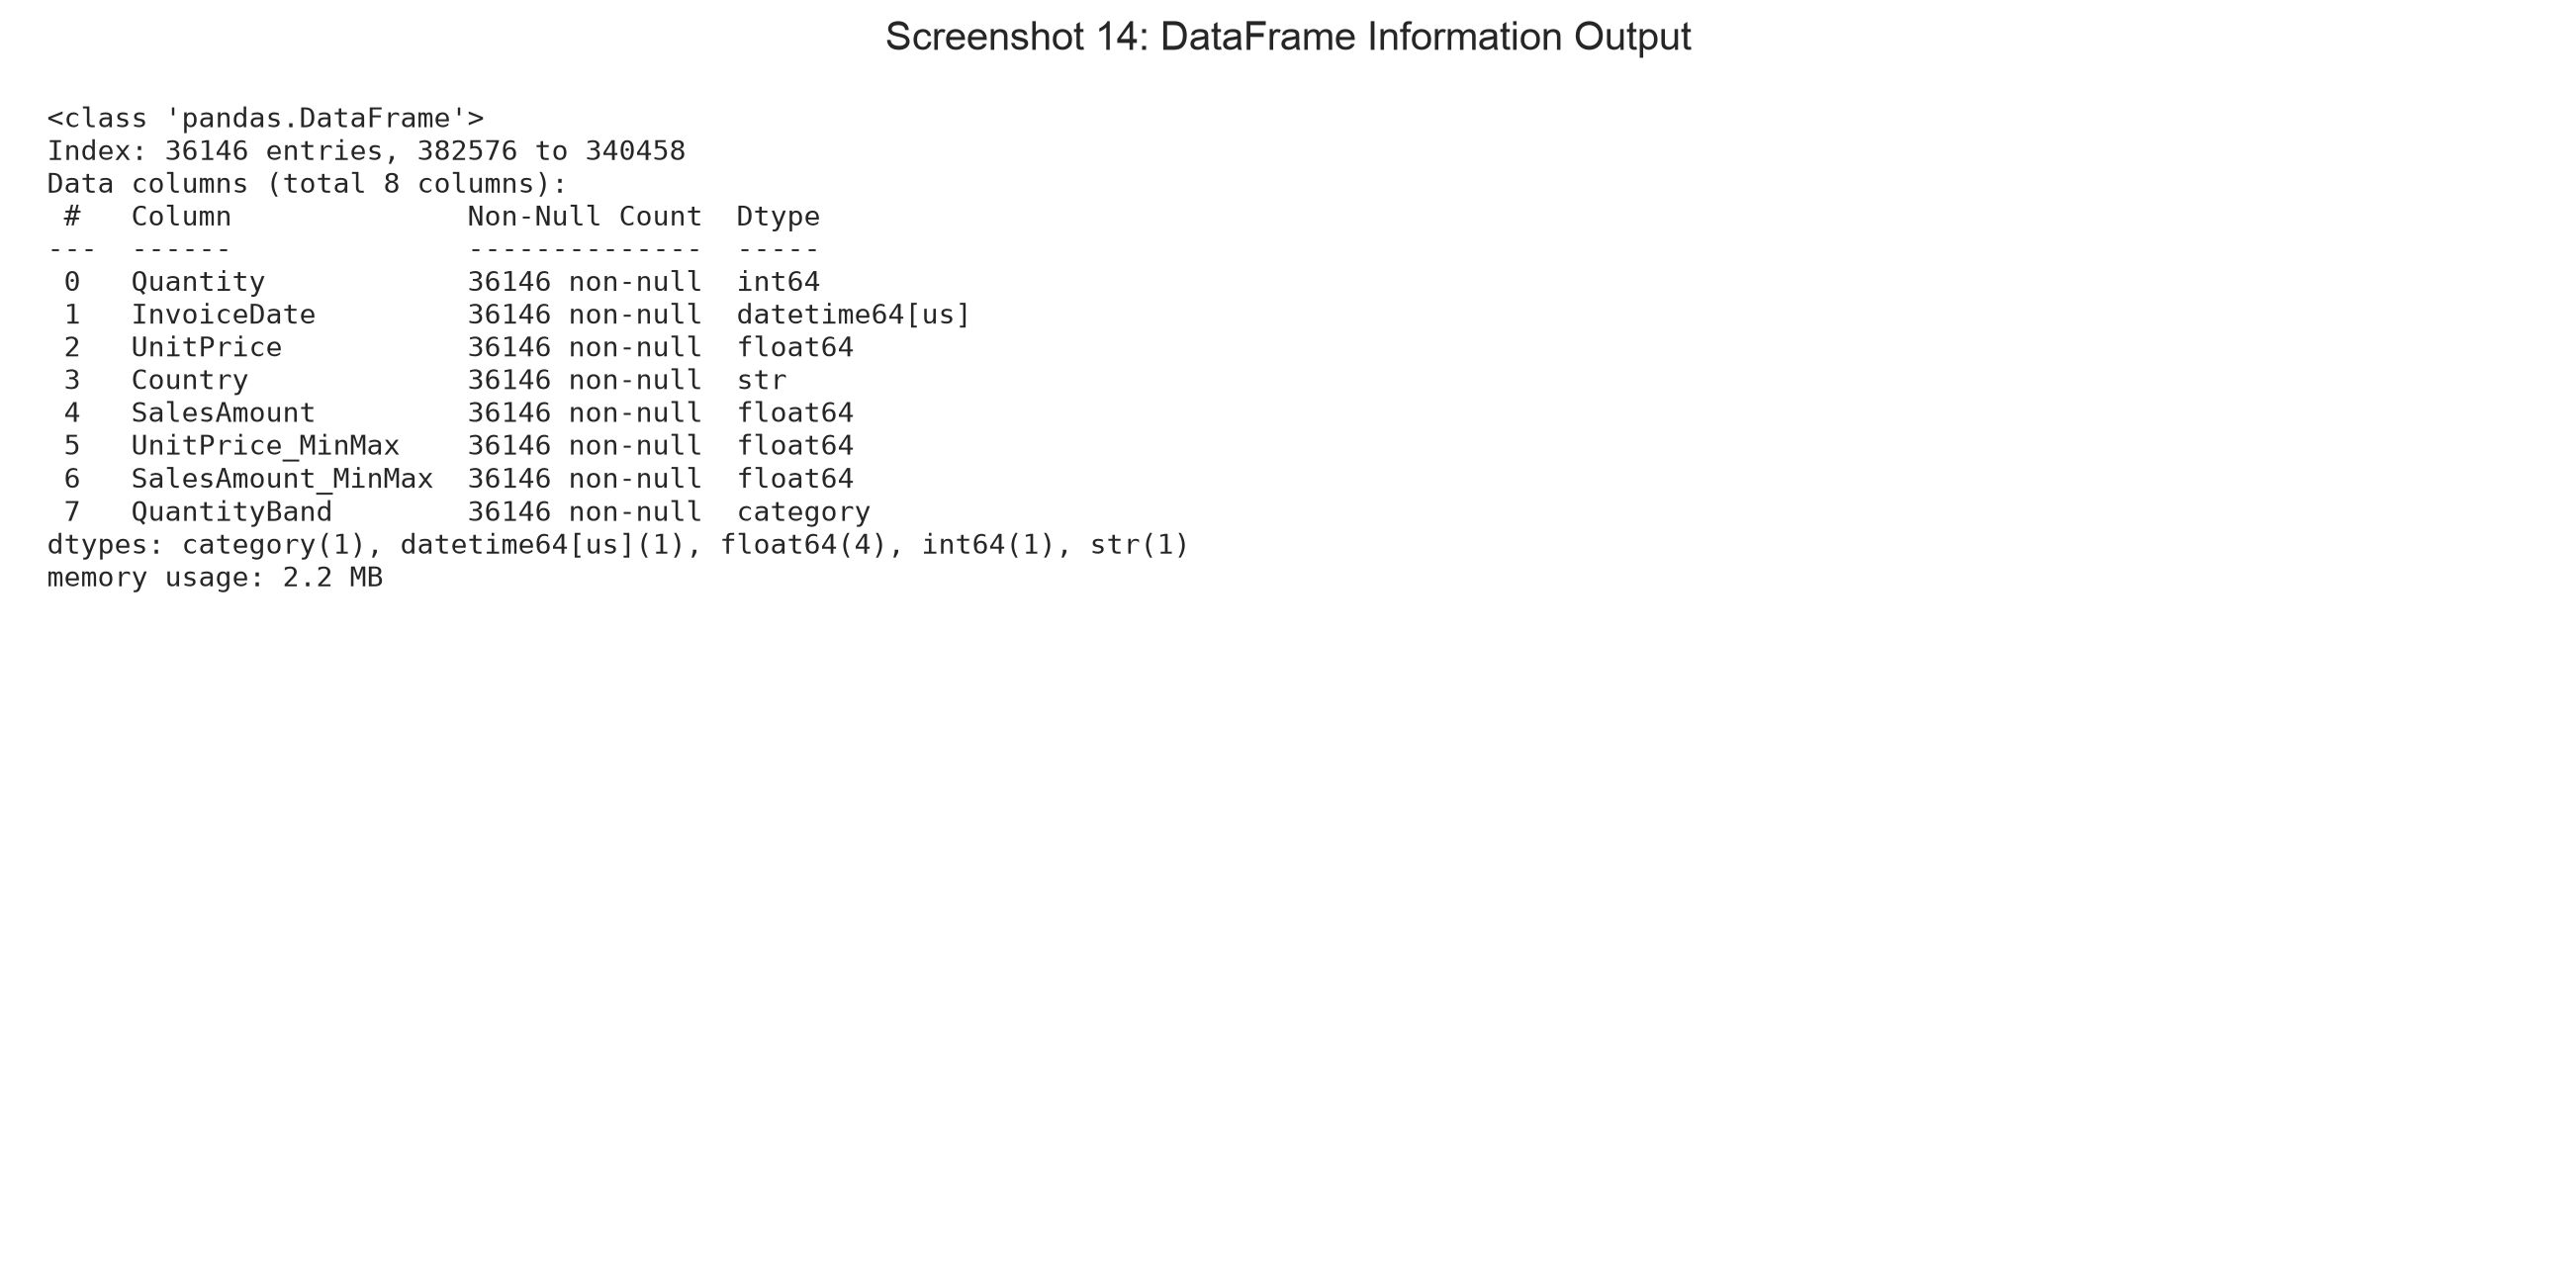


Descriptive statistics


,count,mean,std,min,25%,50%,75%,max
Quantity,"36,146.00",7.92,9.87,1.00,2.00,4.00,12.00,192.00
UnitPrice,"36,146.00",2.75,2.92,0.04,1.25,1.65,3.45,40.00
SalesAmount,"36,146.00",12.13,9.09,0.10,4.25,10.20,17.40,42.00


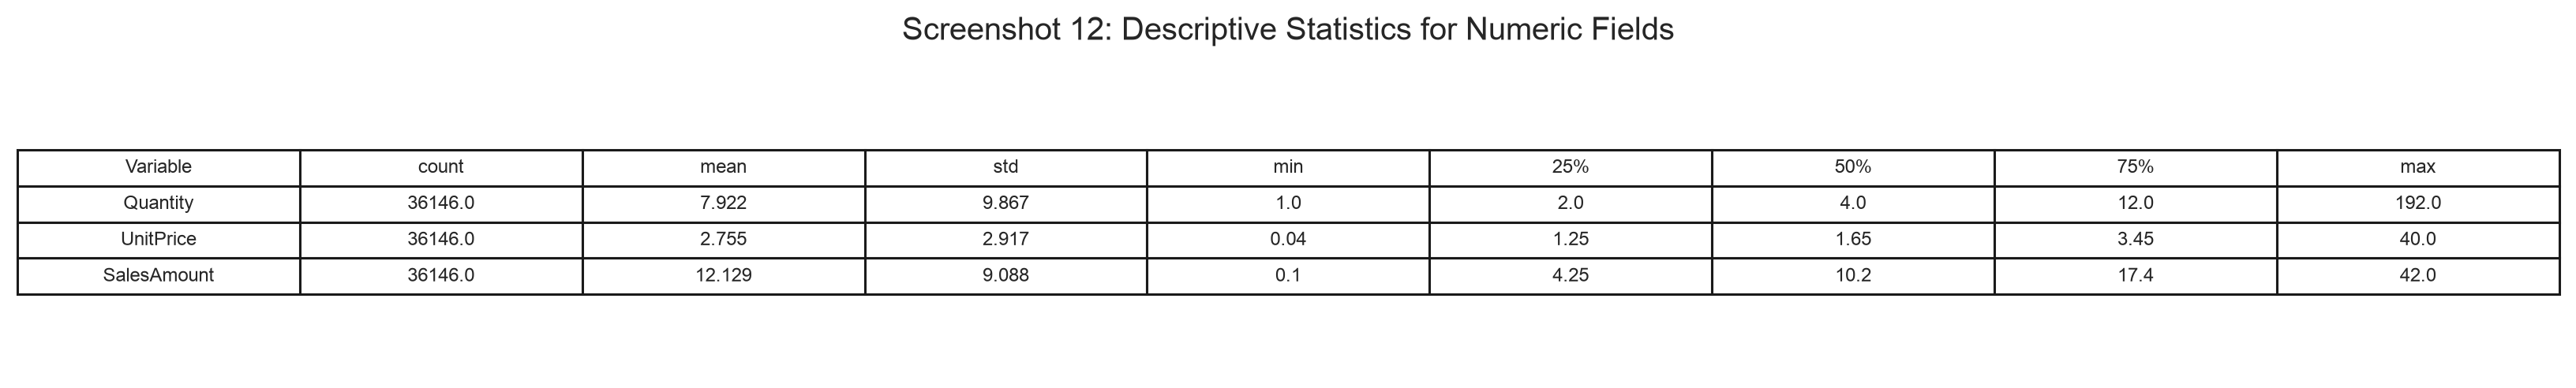

In [9]:
print("DataFrame information")
reduced.info()
import io
info_buffer = io.StringIO()
reduced.info(buf=info_buffer)
info_image = save_text(
    info_buffer.getvalue(),
    "14_info_output.png",
    "Screenshot 14: DataFrame Information Output",
)
display(Image(filename=str(info_image)))
print("\nDescriptive statistics")
descriptive_statistics = reduced[["Quantity", "UnitPrice", "SalesAmount"]].describe().T
display(descriptive_statistics)
overview_image = save_table(
    descriptive_statistics.reset_index().rename(columns={"index": "Variable"}),
    "12_describe_output.png",
    "Screenshot 12: Descriptive Statistics for Numeric Fields",
    max_rows=3,
)
display(Image(filename=str(overview_image)))

,Minimum,Maximum,Mean,Median,Mode
Quantity,1.00,192.00,7.92,4.00,1.00
UnitPrice,0.04,40.00,2.75,1.65,1.25
SalesAmount,0.10,42.00,12.13,10.20,15.00


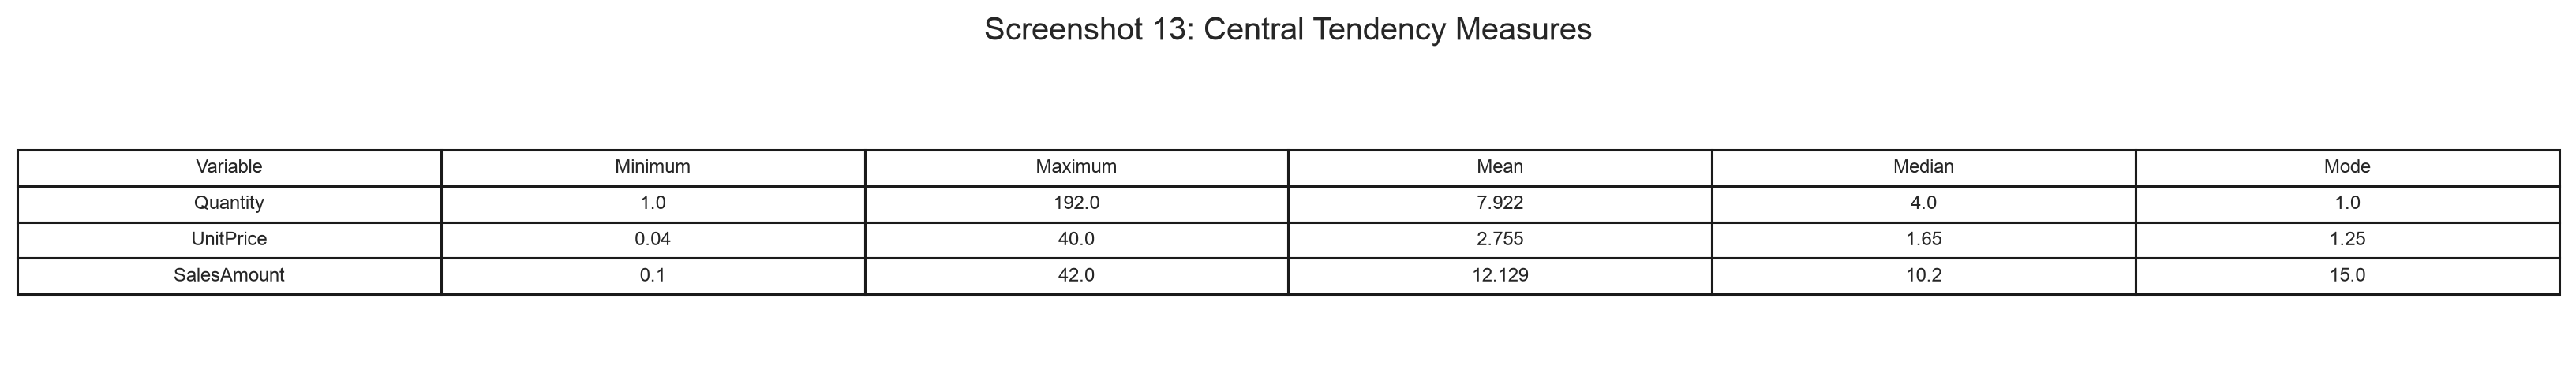

,Range,Q1,Q3,IQR,Variance,Standard deviation
Quantity,191.00,2.00,12.00,10.00,97.36,9.87
UnitPrice,39.96,1.25,3.45,2.20,8.51,2.92
SalesAmount,41.90,4.25,17.40,13.15,82.59,9.09


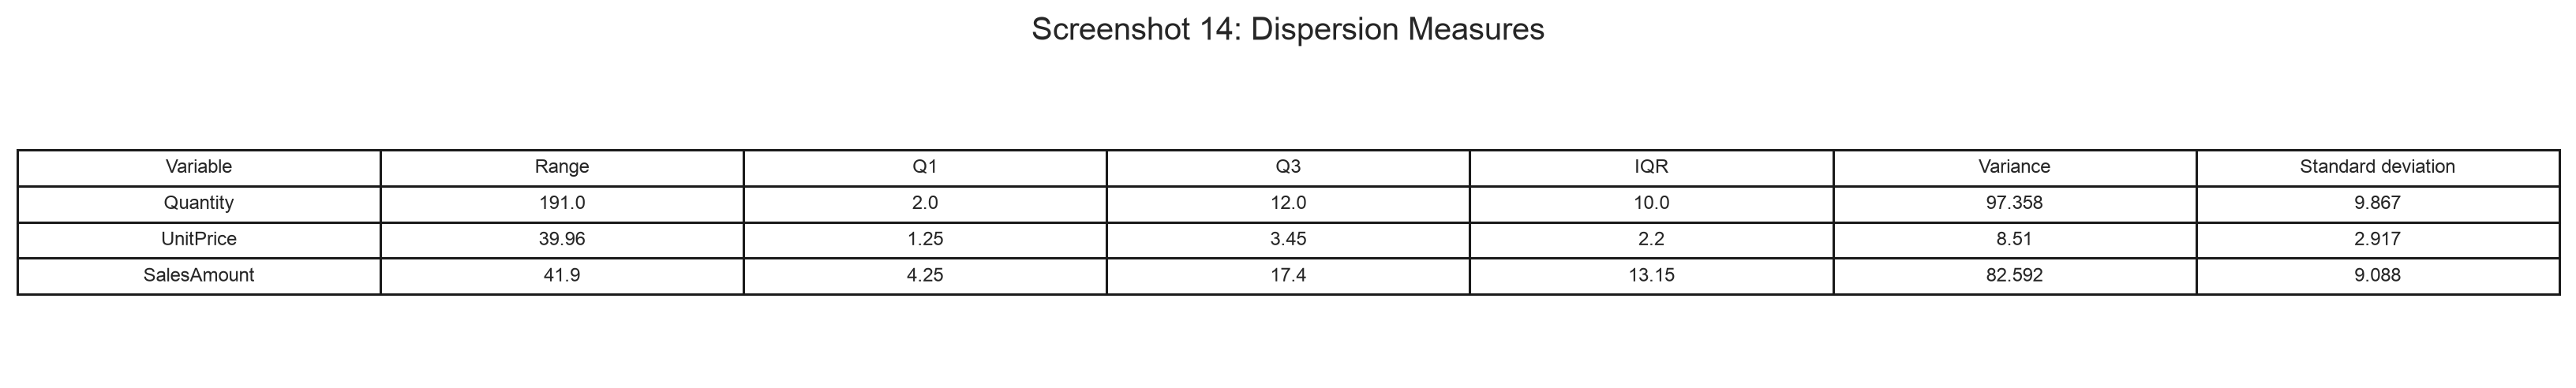

In [10]:
numeric_analysis = reduced[["Quantity", "UnitPrice", "SalesAmount"]]
central_tendency = pd.DataFrame(
    {
        "Minimum": numeric_analysis.min(),
        "Maximum": numeric_analysis.max(),
        "Mean": numeric_analysis.mean(),
        "Median": numeric_analysis.median(),
        "Mode": numeric_analysis.mode().iloc[0],
    }
)
display(central_tendency)
central_image = save_table(
    central_tendency.reset_index().rename(columns={"index": "Variable"}),
    "13_central_tendency.png",
    "Screenshot 13: Central Tendency Measures",
    max_rows=3,
)
display(Image(filename=str(central_image)))

dispersion = pd.DataFrame(
    {
        "Range": numeric_analysis.max() - numeric_analysis.min(),
        "Q1": numeric_analysis.quantile(0.25),
        "Q3": numeric_analysis.quantile(0.75),
        "IQR": numeric_analysis.quantile(0.75) - numeric_analysis.quantile(0.25),
        "Variance": numeric_analysis.var(),
        "Standard deviation": numeric_analysis.std(),
    }
)
display(dispersion)
dispersion_image = save_table(
    dispersion.reset_index().rename(columns={"index": "Variable"}),
    "14_dispersion_measures.png",
    "Screenshot 14: Dispersion Measures",
    max_rows=3,
)
display(Image(filename=str(dispersion_image)))

,Quantity,UnitPrice,SalesAmount
Quantity,1.00,-0.34,0.40
UnitPrice,-0.34,1.00,0.29
SalesAmount,0.40,0.29,1.00


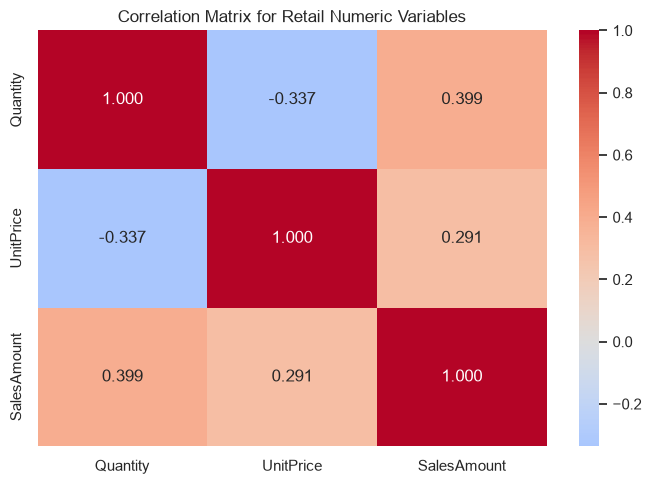

SalesAmount is positively related to both quantity and unit price because it is calculated from those fields. This is expected, so all three fields should not be treated as independent predictors in a later model.


In [11]:
correlation_matrix = numeric_analysis.corr()
display(correlation_matrix)

figure, axis = plt.subplots(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=axis)
axis.set_title("Correlation Matrix for Retail Numeric Variables")
figure.tight_layout()
correlation_file = SCREENSHOT_PATH / "15_correlation_matrix.png"
figure.savefig(correlation_file, dpi=300, bbox_inches="tight")
plt.show()

print(
    "SalesAmount is positively related to both quantity and unit price because it is "
    "calculated from those fields. This is expected, so all three fields should not be "
    "treated as independent predictors in a later model."
)

## Findings and decisions

The visualizations show that retail sales are concentrated in the United Kingdom and that monthly sales increase near the end of 2011. Most sales lines contain smaller quantities and lower prices, while a relatively small number of large orders create a right-skewed sales distribution. This pattern explains why the outlier review used sales amount rather than simply removing high quantities or high prices on their own.

Missing product descriptions were labeled clearly because the transaction itself still has useful numeric information. Records without customer identifiers were removed because customer-level analysis would not be possible for them. The IQR rule removed unusually high sales amounts after cancellation and zero-value lines were excluded. A reproducible 10% sample and the removal of identifier columns reduced the file for this lab, while the raw source file remains available for later work.

Min-Max scaling places unit price and sales amount on a common zero-to-one range. Quantity bands make the continuous order quantity easier to compare as single-item, small, medium, and large orders. The correlation matrix confirms that sales amount is related to its two calculated components. That relationship is expected, but it should be considered when selecting variables for a later predictive model.

## Reference

Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33